In [1]:
import os

dataset_path = "dataset"

for category in ["organic", "recyclable"]:
    path = os.path.join(dataset_path, category)
    images = os.listdir(path)
    print(category, ":", len(images), "images")
    

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'dataset\\organic'

In [2]:
import os

print("Current location:", os.getcwd())
print("Available folders:", os.listdir())

Current location: C:\Users\Avinash Helker\Desktop\Smart_Waste_Classification\notebooks
Available folders: ['.ipynb_checkpoints', 'Waste_Classification.ipynb']


In [3]:
dataset_path = r"C:\Users\Avinash Helker\Desktop\Smart_Waste_Classification\dataset"

for category in ["organic", "recyclable"]:
    path = os.path.join(dataset_path, category)
    print(category, ":", len(os.listdir(path)), "images")

organic : 0 images
recyclable : 0 images


In [4]:
import os

dataset_path = os.path.join("..", "dataset")

for category in ["organic", "recyclable"]:
    path = os.path.join(dataset_path, category)
    print(category, ":", len(os.listdir(path)), "images")

organic : 0 images
recyclable : 0 images


In [5]:
import os

source_path = r"C:\Users\Avinash Helker\Downloads\DATASET\TRAIN"

print("Source exists:", os.path.exists(source_path))

if os.path.exists(source_path):
    print("Folders:", os.listdir(source_path))

    for folder in os.listdir(source_path):
        folder_path = os.path.join(source_path, folder)
        if os.path.isdir(folder_path):
            print(folder, ":", len(os.listdir(folder_path)), "files")

Source exists: False


In [6]:
import os
import shutil
import glob

source_path = r"C:\Users\Avinash Helker\Downloads\archive\DATASET\TRAIN"
destination_path = r"..\dataset"

for category, folder in [("organic", "O"), ("recyclable", "R")]:
    source_folder = os.path.join(source_path, folder)
    destination_folder = os.path.join(destination_path, category)

    os.makedirs(destination_folder, exist_ok=True)

    images = glob.glob(os.path.join(source_folder, "*"))

    for image in images[:200]:
        if os.path.isfile(image):
            shutil.copy2(image, destination_folder)

    print(category, ":", len(os.listdir(destination_folder)), "images")

print("Dataset copied successfully!")

organic : 200 images
recyclable : 200 images
Dataset copied successfully!


In [7]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import os

from tensorflow.keras.preprocessing.image import ImageDataGenerator

dataset_path = "../dataset"

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_data = datagen.flow_from_directory(
    dataset_path,
    target_size=(128, 128),
    batch_size=16,
    class_mode="binary",
    subset="training"
)

val_data = datagen.flow_from_directory(
    dataset_path,
    target_size=(128, 128),
    batch_size=16,
    class_mode="binary",
    subset="validation"
)

print("Class labels:", train_data.class_indices)

Found 320 images belonging to 2 classes.
Found 80 images belonging to 2 classes.
Class labels: {'organic': 0, 'recyclable': 1}


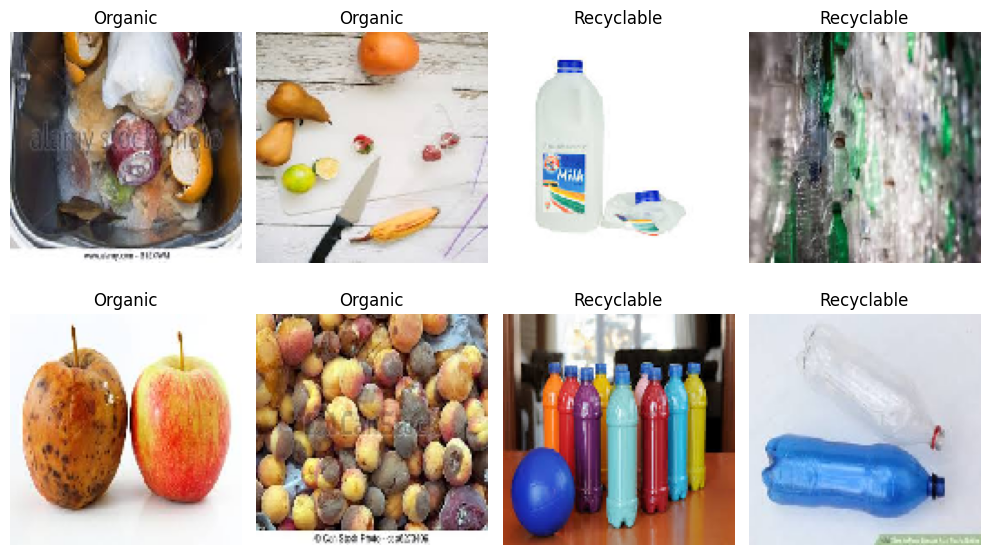

In [8]:
images, labels = next(train_data)

plt.figure(figsize=(10, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i])
    plt.title("Recyclable" if labels[i] == 1 else "Organic")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
history = model.fit(
    train_data,
    epochs=10,
    validation_data=val_data
)

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 12s 377ms/step - accuracy: 0.6375 - loss: 0.7222 - val_accuracy: 0.7875 - val_loss: 0.4365
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 268ms/step - accuracy: 0.8469 - loss: 0.4183 - val_accuracy: 0.8000 - val_loss: 0.3883
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 270ms/step - accuracy: 0.8344 - loss: 0.4101 - val_accuracy: 0.7750 - val_loss: 0.4408
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 266ms/step - accuracy: 0.8406 - loss: 0.4057 - val_accuracy: 0.7875 - val_loss: 0.4592
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 277ms/step - accuracy: 0.8938 - loss: 0.3598 - val_accuracy: 0.7750 - val_loss: 0.4139
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 275ms/step - accuracy: 0.8719 - loss: 0.3360 - val_accuracy: 0.8375 - val_loss: 0.3971
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 270ms/step - accuracy: 0.9250 - loss: 0.2538 - val_accuracy: 0.7750 - val_loss: 0.4810
Epoch 8/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 272ms/step - accuracy: 0.9156 - loss: 0.2272 - val_accuracy: 

In [11]:
train_loss, train_accuracy = model.evaluate(train_data)
val_loss, val_accuracy = model.evaluate(val_data)

print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")

20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - accuracy: 0.9531 - loss: 0.1132
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step - accuracy: 0.8125 - loss: 0.6413
Training Accuracy: 95.31 %
Validation Accuracy: 81.25 %


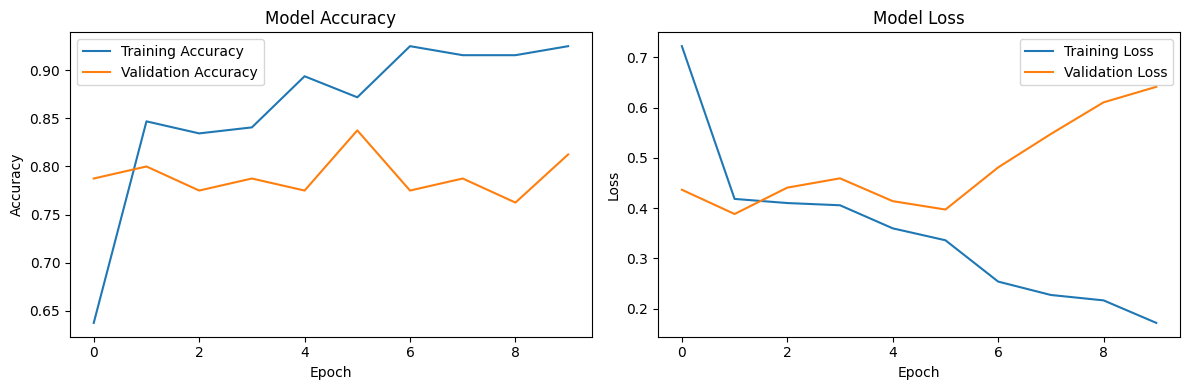

In [12]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
os.makedirs("../models", exist_ok=True)

model.save("../models/waste_classifier.keras")

print("Model saved successfully!")

Model saved successfully!


In [14]:
print(os.path.exists("../models/waste_classifier.keras"))

True


In [15]:
%%writefile ../app/app.py

import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image

st.set_page_config(
    page_title="Smart Waste Classification",
    page_icon="♻️",
    layout="centered"
)

st.title("♻️ Smart Waste Classification")
st.write("Upload a waste image to classify it.")

@st.cache_resource
def load_model():
    return tf.keras.models.load_model(
        "../models/waste_classifier.keras"
    )

model = load_model()

uploaded_file = st.file_uploader(
    "Upload Waste Image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:

    image = Image.open(uploaded_file).convert("RGB")

    st.image(image, caption="Uploaded Image", width=300)

    image = image.resize((128, 128))

    image_array = np.array(image) / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    prediction = model.predict(image_array)[0][0]

    if prediction >= 0.5:
        category = "Recyclable Waste"
        confidence = prediction * 100
    else:
        category = "Organic Waste"
        confidence = (1 - prediction) * 100

    st.success(f"Prediction: {category}")
    st.metric("Confidence", f"{confidence:.2f}%")

Writing ../app/app.py
